# ConvNeXt Small + Query2Label — Nutrition5k, 100 clases

Notebook basado en `COLAB_QUERY2LABEL.md`. Arquitectura: consultas de atención, MLP compartido 768 → 384 → 192, ASL/BCE y ajuste de la última etapa del encoder después de 3 épocas de warmup.

La pérdida de masa total se divide por la media de **train**, calculada al preparar la corrida (≈219,11 g con los datos actuales); la pérdida de gramos de ingredientes conserva 300 g. No fijar 219,11 manualmente.

Las celdas de entrenamiento están desactivadas por defecto. Primero ejecutar preparación y verificación; después habilitar explícitamente la corrida deseada. Evaluación e inferencia también son opcionales. Elegir **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU** antes de comenzar.


## Antes de Colab: archivos en Git y Drive

**Git:** subir `src/`, `scripts/`, `config/`, `tests/`, `requirements.txt`, `pyproject.toml`, `.gitignore`, los documentos del proyecto y este notebook. Conservar la estructura interna de IngredientMassEstimation. El repositorio puede contener esta carpeta o publicarla directamente en su raíz. No subir datos, entornos, cachés, pesos ni resultados.

**Drive:** crear `MyDrive/IngredientMassEstimation/` y subir `nutrition5k_rgb.zip`. El ZIP debe contener `nutrition5k_dataset/metadata`, `nutrition5k_dataset/dish_ids` y `nutrition5k_dataset/imagery/realsense_overhead`.

En PowerShell, desde la carpeta local del proyecto (ejecutar manualmente; reutilizar un ZIP existente):

```powershell
Compress-Archive -LiteralPath ".\data\raw\nutrition5k_dataset" -DestinationPath ".\data\nutrition5k_rgb.zip"
```

Para continuar una corrida local, subir **todo el contenido** de `artifacts/query2label_100_asl/` a `MyDrive/IngredientMassEstimation/runs/query2label_100_asl/`: `last.pt`, `best.pt`, `history.csv`, `config.json` y `latest_validation.json`. Así se conserva también el mejor modelo previo aunque las siguientes épocas no mejoren. No hace falta copiar `data/processed_100`: se regenera con los mismos datos, seed y configuración.


## Opcional: una época local en CPU

Estos comandos son una referencia para ejecutar **manualmente en PowerShell**, no una celda de Colab. Desde IngredientMassEstimation, usando el entorno disponible de OmniFood:

```powershell
$pythonExe = "..\OmniFood8K\Code\.venv\Scripts\python.exe"
& $pythonExe scripts/prepare_nutrition5k.py --config config/query2label_100.json --output-dir data/processed_100
& $pythonExe scripts/train_image_model.py --check-data
& $pythonExe -u scripts/train_image_model.py --config config/query2label_100.json --device cpu --workers 0 --epochs 1 --output-dir artifacts/query2label_100_asl
```

La tercera línea entrena una época completa y puede tardar mucho en CPU; requiere descargar inicialmente los pesos ImageNet. Mantener batch 8, acumulación 4 y el resto de la configuración para continuar en Colab. AMP se desactiva automáticamente en CPU, sin cambiar `amp: true` en el config. Si la carpeta de salida ya contiene una corrida, usar otra carpeta o reanudar conscientemente.

Después subir la carpeta de la corrida a Drive y usar modo `resume` abajo. `TOTAL_EPOCHS = 30` continúa desde la época 2 hasta un máximo total de 30 (sujeto a early stopping); `2` permite probar solamente la siguiente época. Cambiar dispositivo y workers no da identidad bit a bit.


## 1. GPU y Drive

In [1]:
import torch
assert torch.cuda.is_available(), "Este runtime no tiene GPU CUDA. Cambiá el entorno de ejecución."
print(torch.cuda.get_device_name(0))
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 2. Obtener el código

Reemplazar `URL` por el repositorio publicado. Para un repo privado, agregar `GITHUB_TOKEN` a los secretos de Colab y habilitar acceso al notebook. Para un repo público, elegir `PRIVATE_REPO = False`. No pegar credenciales en el código.


In [2]:
from pathlib import Path
import base64, os, subprocess, sys

REPO = Path("/content/nutrition-code")
URL = "https://github.com/marcogloazzo/IngredientMassEstimation.git"
PRIVATE_REPO = False

assert "TU_USUARIO" not in URL and "TU_REPOSITORIO" not in URL, "Completá URL con tu repositorio."
environment = os.environ.copy()
if PRIVATE_REPO:
    from google.colab import userdata
    token = userdata.get("GITHUB_TOKEN")
    assert token, "Configurá el secreto GITHUB_TOKEN."
    authorization = base64.b64encode(f"x-access-token:{token}".encode()).decode()
    environment.update({"GIT_CONFIG_COUNT": "1", "GIT_CONFIG_KEY_0": "http.extraHeader",
                        "GIT_CONFIG_VALUE_0": f"Authorization: Basic {authorization}"})
try:
    command = (["git", "-C", str(REPO), "pull", "--ff-only"] if (REPO / ".git").exists()
               else ["git", "clone", URL, str(REPO)])
    result = subprocess.run(command, env=environment, capture_output=True, text=True)
    if result.returncode:
        raise RuntimeError("Git falló. Verificá URL, permisos del token y cambios locales; no se imprime la credencial.")
finally:
    del environment
    if PRIVATE_REPO:
        del token, authorization

candidates = [REPO / "IngredientMassEstimation", REPO]
PROJECT = next((p for p in candidates if (p / "config/query2label_100.json").is_file()), None)
assert PROJECT is not None, "El repositorio no contiene la nueva variante."
os.chdir(PROJECT)
print("Project:", PROJECT)

Project: /content/nutrition-code


## 3. Dependencias mínimas

Usar PyTorch/torchvision con CUDA del runtime. No copiar el entorno Windows ni instalar los paquetes de OmniFood.

In [3]:
subprocess.run([sys.executable, "-m", "pip", "install", "Pillow>=10,<13", "tqdm>=4.66,<5"], check=True)
import torch, torchvision, numpy
assert hasattr(torch.amp, "GradScaler"), "Hace falta PyTorch >= 2.3."
assert torch.cuda.is_available()
print("Torch:", torch.__version__, "Torchvision:", torchvision.__version__, "NumPy:", numpy.__version__)

Torch: 2.11.0+cu130 Torchvision: 0.26.0+cu130 NumPy: 2.1.3


## 4. Copiar y extraer los datos en /content

El dataset se lee desde el almacenamiento local de Colab. Drive conserva ZIP, checkpoints y resultados entre sesiones.

In [6]:
from pathlib import Path

destination = Path("/content/nutrition5k")
candidates = [
    p.parent
    for p in destination.rglob("metadata")
    if p.is_dir()
    and (p.parent / "dish_ids").is_dir()
    and (p.parent / "imagery/realsense_overhead").is_dir()
]

assert len(candidates) == 1, f"No se encontró una raíz única del dataset: {candidates}"
DATA = candidates[0]
print("Dataset encontrado:", DATA)

AssertionError: No se encontró una raíz única del dataset: []

In [7]:
with zipfile.ZipFile(DRIVE / "nutrition5k_rgb.zip") as z:
    print("\n".join(
        name for name in z.namelist()
        if "metadata" in name
    )[:3000])

nutrition5k_dataset\metadata\dish_metadata_cafe1.csv
nutrition5k_dataset\metadata\dish_metadata_cafe2.csv
nutrition5k_dataset\metadata\ingredients_metadata.csv


In [8]:
from pathlib import Path
import shutil, zipfile

DRIVE = Path("/content/drive/MyDrive/IngredientMassEstimation")
DATA = Path("/content/nutrition5k/nutrition5k_dataset")
archive = Path("/content/nutrition5k_rgb.zip")
destination = DATA.parent
destination.mkdir(parents=True, exist_ok=True)

if not archive.is_file():
    shutil.copy2(DRIVE / "nutrition5k_rgb.zip", archive)

with zipfile.ZipFile(archive) as source:
    for entry in source.infolist():
        name = entry.filename.replace("\\", "/")
        target = (destination / name).resolve()

        if not target.is_relative_to(destination.resolve()):
            raise ValueError(f"Ruta insegura en el ZIP: {name}")

        if entry.is_dir() or name.endswith("/"):
            target.mkdir(parents=True, exist_ok=True)
        else:
            target.parent.mkdir(parents=True, exist_ok=True)
            with source.open(entry) as src, target.open("wb") as dst:
                shutil.copyfileobj(src, dst)

for folder in ("metadata", "dish_ids", "imagery/realsense_overhead"):
    assert (DATA / folder).is_dir(), f"Falta: {folder}"

print("Dataset:", DATA)

Dataset: /content/nutrition5k/nutrition5k_dataset


## 5. Preparar etiquetas y verificar sin entrenar

Esperado: 100 clases, 2332 train, 423 validación y 507 test. La comprobación calcula la escala de masa de train, sin cargar el modelo ni descargar pesos.

In [9]:
import json

CONFIG = "config/query2label_100.json"
PROCESSED = "data/processed_100"
subprocess.run([sys.executable, "scripts/prepare_nutrition5k.py",
                "--config", CONFIG, "--dataset-root", str(DATA),
                "--output-dir", PROCESSED], check=True)
checked = subprocess.run([sys.executable, "scripts/train_image_model.py", "--check-data",
                          "--config", CONFIG, "--processed-dir", PROCESSED,
                          "--dataset-root", str(DATA)], check=True, capture_output=True, text=True)
print(checked.stdout)
verification = json.loads(checked.stdout)
assert verification["classes"] == 100
assert verification["splits"] == {"train": 2332, "validation": 423, "test": 507}, "El dataset difiere del local."
assert verification["config"]["mass_normalization"] == "train_mean"
assert verification["config"]["ingredient_mass_scale"] == 300.0
print("Escala de masa total (train):", verification["config"]["mass_scale"], "g")

{
  "config": {
    "model_type": "convnext_small_query2label",
    "seed": 42,
    "top_k": 100,
    "validation_fraction": 0.15,
    "encoder": "convnext_small",
    "encoder_training": "last_stage",
    "attention_dim": 256,
    "attention_heads": 4,
    "attention_layers": 1,
    "attention_feedforward": 1024,
    "attention_dropout": 0.1,
    "shared_dims": [
      384,
      192
    ],
    "mass_hidden_dim": 128,
    "dropout": 0.3,
    "presence_loss": "asl",
    "asl": {
      "gamma_neg": 4.0,
      "gamma_pos": 1.0,
      "clip": 0.05,
      "detach_focal_weight": true
    },
    "batch_size": 8,
    "accumulation_steps": 4,
    "epochs": 30,
    "warmup_epochs": 3,
    "learning_rate": 0.0003,
    "encoder_learning_rate": 1e-05,
    "weight_decay": 0.001,
    "patience": 8,
    "selection_metric": "ingredient_mass_l1_per_plate",
    "presence_threshold": 0.5,
    "amp": true,
    "max_grad_norm": 1.0,
    "ingredient_mass_scale": 300.0,
    "mass_normalization": "train_mean"

## 6. Entrenar ASL o continuar desde CPU/Colab

Elegir `MODE = "new"` para comenzar de cero en una carpeta vacía, o `"resume"` para continuar desde `last.pt` subido a Drive. Definir primero `TOTAL_EPOCHS` y luego habilitar `RUN_TRAINING` cuando quieras entrenar. El directorio ya usado no se sobrescribe con una corrida nueva.

Los pesos iniciales ImageNet (~192 MB) se guardan en `torch_cache`. Cada cierre de época guarda `best.pt`, `last.pt` y el historial en Drive. Una interrupción a mitad de época obliga a repetirla. Conservar la misma configuración al reanudar: solo puede cambiar el límite total de épocas. No mezclar ASL y BCE.


In [14]:
RUN_TRAINING = True  # Cambiar a True solamente cuando quieras ejecutar entrenamiento.
MODE = "resume"        # "new" para empezar desde cero; "resume" para continuar last.pt.
TOTAL_EPOCHS = 100      # Límite TOTAL, no cantidad de épocas adicionales.
RUN = DRIVE / "runs/query2label_100_asl"

arguments = [sys.executable, "-u", "scripts/train_image_model.py",
             "--config", CONFIG, "--processed-dir", PROCESSED,
             "--dataset-root", str(DATA), "--output-dir", str(RUN),
             "--torch-cache", str(DRIVE / "torch_cache"),
             "--device", "cuda", "--workers", "2", "--epochs", str(TOTAL_EPOCHS)]

if RUN_TRAINING:
    assert MODE in ("new", "resume"), "MODE debe ser new o resume."
    training_arguments = arguments.copy()
    if MODE == "resume":
        assert (RUN / "last.pt").is_file(), "Subí la corrida local o elegí MODE = new."
        assert (RUN / "best.pt").is_file(), "Subí también best.pt para conservar el mejor modelo previo."
        training_arguments += ["--resume", str(RUN / "last.pt")]
    else:
        assert not RUN.exists() or not any(RUN.iterdir()), "Usá otra carpeta para una corrida nueva."
    with subprocess.Popen(
        training_arguments,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    ) as process:
        for line in process.stdout:
            print(line, end="", flush=True)

        returncode = process.wait()
        if returncode:
            raise subprocess.CalledProcessError(returncode, training_arguments)
else:
    print("Entrenamiento desactivado. Revisá MODE, TOTAL_EPOCHS y RUN antes de habilitarlo.")

Device: cuda; presence loss: asl; classes: 100
Total-mass loss scale (training mean): 219.106346 g
Effective batch: 8 x 4; selection: ingredient_mass_l1_per_plate
Epoch 61: encoder last stage trainable

Train 61: 100%|██████████| 292/292 [01:09<00:00,  4.18batch/s, loss=0.6048, samples=2332/2332]

Validation 61: 100%|██████████| 53/53 [00:08<00:00,  6.13batch/s, loss=0.7435, samples=423/423]
F1=0.507; ingredient L1/plate=137.7 g; mass MAE=29.6 g; calories MAE=61.5 kcal; epoch=79 s
Epoch 62: encoder last stage trainable

Train 62: 100%|██████████| 292/292 [01:13<00:00,  3.98batch/s, loss=0.6038, samples=2332/2332]

Validation 62: 100%|██████████| 53/53 [00:06<00:00,  8.15batch/s, loss=0.7291, samples=423/423]
F1=0.510; ingredient L1/plate=133.2 g; mass MAE=29.5 g; calories MAE=60.7 kcal; epoch=80 s
Epoch 63: encoder last stage trainable

Train 63: 100%|██████████| 292/292 [01:13<00:00,  4.00batch/s, loss=0.6014, samples=2332/2332]

Validation 63: 100%|██████████| 53/53 [00:08<00:00,  6.

### Revisar el progreso

El ajuste del encoder empieza en época 4. Observar tiempo por época y unidades de Colab antes de completar 30 épocas. Para una **corrida nueva** con menos memoria, usar un config con batch 4 y acumulación 8; no cambiar esos valores al reanudar una corrida existente.


In [15]:
import csv

history = RUN / "history.csv"
if history.is_file():
    with history.open(newline="", encoding="utf-8") as source:
        rows = list(csv.DictReader(source))
    for row in rows[-5:]:
        print(row)
    if rows:
        print("Última época:", rows[-1]["epoch"], "| segundos:", rows[-1]["seconds"])
else:
    print("Todavía no hay historial en", RUN)

{'epoch': '70', 'encoder_trainable': 'True', 'seconds': '80.79225564300032', 'train_loss': '0.5767349522580004', 'validation_loss': '0.7273862161816717', 'micro_f1': '0.5178382942790796', 'ingredient_mass_l1_per_plate': '133.64987182617188', 'total_mass_mae': '28.71522331237793', 'calorie_mae': '62.387245178222656'}
{'epoch': '71', 'encoder_trainable': 'True', 'seconds': '79.3883141740007', 'train_loss': '0.5713192252617962', 'validation_loss': '0.7225149475372711', 'micro_f1': '0.5085192697768762', 'ingredient_mass_l1_per_plate': '132.5234375', 'total_mass_mae': '29.094816207885742', 'calorie_mae': '56.50372314453125'}
{'epoch': '72', 'encoder_trainable': 'True', 'seconds': '84.54248776500026', 'train_loss': '0.5718283664761031', 'validation_loss': '0.7173171807124541', 'micro_f1': '0.5060584461867427', 'ingredient_mass_l1_per_plate': '133.51060485839844', 'total_mass_mae': '27.676362991333008', 'calorie_mae': '58.43098831176758'}
{'epoch': '73', 'encoder_trainable': 'True', 'seconds'

## 7. Opcional: comparar con BCE

Corrida separada, con los mismos datos, seed y arquitectura. Habilitar solo si el presupuesto lo permite. Seleccionar ASL/BCE con validación. Si ya hay una corrida BCE, elegir `BCE_MODE = "resume"`.


In [16]:
RUN_BCE_TRAINING = False
BCE_MODE = "new"
RUN_BCE = DRIVE / "runs/query2label_100_bce"
bce_arguments = [sys.executable, "-u", "scripts/train_image_model.py",
                 "--config", CONFIG, "--processed-dir", PROCESSED,
                 "--dataset-root", str(DATA), "--output-dir", str(RUN_BCE),
                 "--torch-cache", str(DRIVE / "torch_cache"), "--device", "cuda",
                 "--workers", "2", "--presence-loss", "bce", "--epochs", str(TOTAL_EPOCHS)]
if RUN_BCE_TRAINING:
    assert BCE_MODE in ("new", "resume")
    if BCE_MODE == "resume":
        assert (RUN_BCE / "last.pt").is_file() and (RUN_BCE / "best.pt").is_file()
        bce_arguments += ["--resume", str(RUN_BCE / "last.pt")]
    else:
        assert not RUN_BCE.exists() or not any(RUN_BCE.iterdir()), "Usá otra carpeta o reanudá."
    subprocess.run(bce_arguments, check=True)
else:
    print("Comparación BCE desactivada.")

Comparación BCE desactivada.


## 8. Calibrar con validación y evaluar test

Ejecutar después de elegir la variante con validación. Estas rutas corresponden a ASL. El umbral calibrado cambia los reportes de presencia; no recorta las proporciones ni cambia los nutrientes.

In [17]:
RUN_CALIBRATION = True
VALIDATION = DRIVE / "reports/query2label_asl_validation"
CHECKPOINT = VALIDATION / "calibrated.pt"
if RUN_CALIBRATION:
    assert (RUN / "best.pt").is_file(), "Primero necesitás un modelo entrenado."
    subprocess.run([sys.executable, "scripts/evaluate_image_model.py",
                    "--checkpoint", str(RUN / "best.pt"), "--dataset-root", str(DATA),
                    "--processed-dir", PROCESSED, "--split", "validation", "--calibrate",
                    "--output-dir", str(VALIDATION), "--device", "cuda"], check=True)
else:
    print("Calibración desactivada.")

In [18]:
RUN_TEST_EVALUATION = True
if RUN_TEST_EVALUATION:
    assert CHECKPOINT.is_file(), "Primero calibrá con validación."
    subprocess.run([sys.executable, "scripts/evaluate_image_model.py",
                    "--checkpoint", str(CHECKPOINT), "--dataset-root", str(DATA),
                    "--processed-dir", PROCESSED, "--split", "test",
                    "--output-dir", str(DRIVE / "reports/query2label_asl_test"),
                    "--device", "cuda"], check=True)
else:
    print("Evaluación de test desactivada.")

In [19]:
path = DRIVE / "reports/query2label_asl_test/metrics.json"
print(json.dumps(json.loads(path.read_text()), indent=2))

{
  "ingredient_recognition": {
    "micro_precision": 0.6274384393987847,
    "micro_recall": 0.5677083333333334,
    "micro_f1": 0.5960808142184415,
    "macro_f1": 0.38251421480846104,
    "exact_match": 0.28007889546351084
  },
  "end_to_end_lightweight_mass": {
    "share_mae_percentage_points": 0.7114006280899048,
    "ingredient_mass_mae_present_grams": 15.732621192932129,
    "ingredient_mass_l1_per_plate_grams": 145.95973205566406,
    "ingredient_mass_mae_all_classes_grams": 1.4595972299575806,
    "false_ingredient_mass_per_plate_grams": 38.71724319458008,
    "total_mass_mae_grams": 37.93452072143555,
    "total_mass_pmae": 0.19109736034314018,
    "nutrients": {
      "calories": {
        "mae": 67.08000946044922,
        "pmae": 0.26257795427639496
      },
      "fat": {
        "mae": 4.920238018035889,
        "pmae": 0.38347501804836287
      },
      "carbohydrates": {
        "mae": 7.046170711517334,
        "pmae": 0.3579717152980211
      },
      "protein": {
 

## 9. Foto del celular e intermedios

Subir una foto a `MyDrive/IngredientMassEstimation/photos/plato.png`. Se exportan JSON, crop, tensores y mapas de atención. La atención no es segmentación ni prueba de presencia; una foto fuera de Nutrition5k puede tener errores por cambio de dominio.

In [25]:
RUN_INFERENCE = True
PHOTO = DRIVE / "photos/IMG_9977.png"
if RUN_INFERENCE:
    assert CHECKPOINT.is_file(), "Falta el checkpoint calibrado."
    assert PHOTO.is_file(), f"Subí una foto a {PHOTO}"
    subprocess.run([sys.executable, "scripts/infer_image_model.py",
                    "--checkpoint", str(CHECKPOINT), "--image", str(PHOTO),
                    "--output-dir", str(DRIVE / "predictions"), "--device", "cuda",
                    "--save-attention", "--top-k", "10"], check=True)
else:
    print("Inferencia desactivada.")

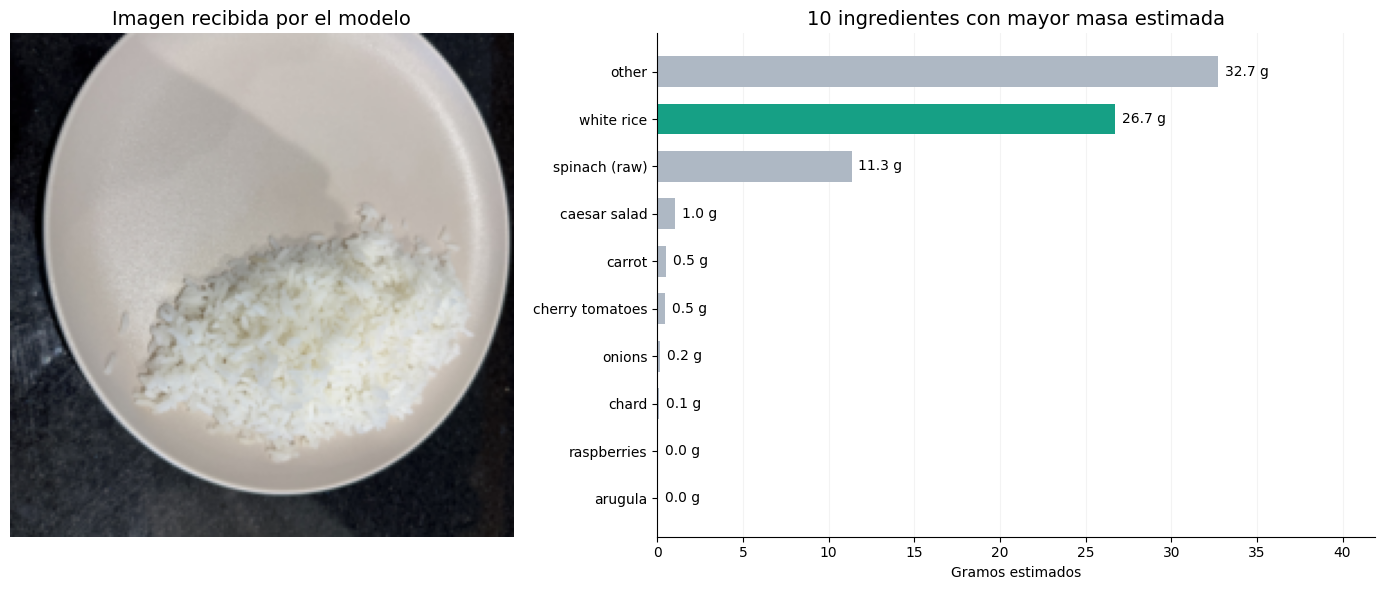

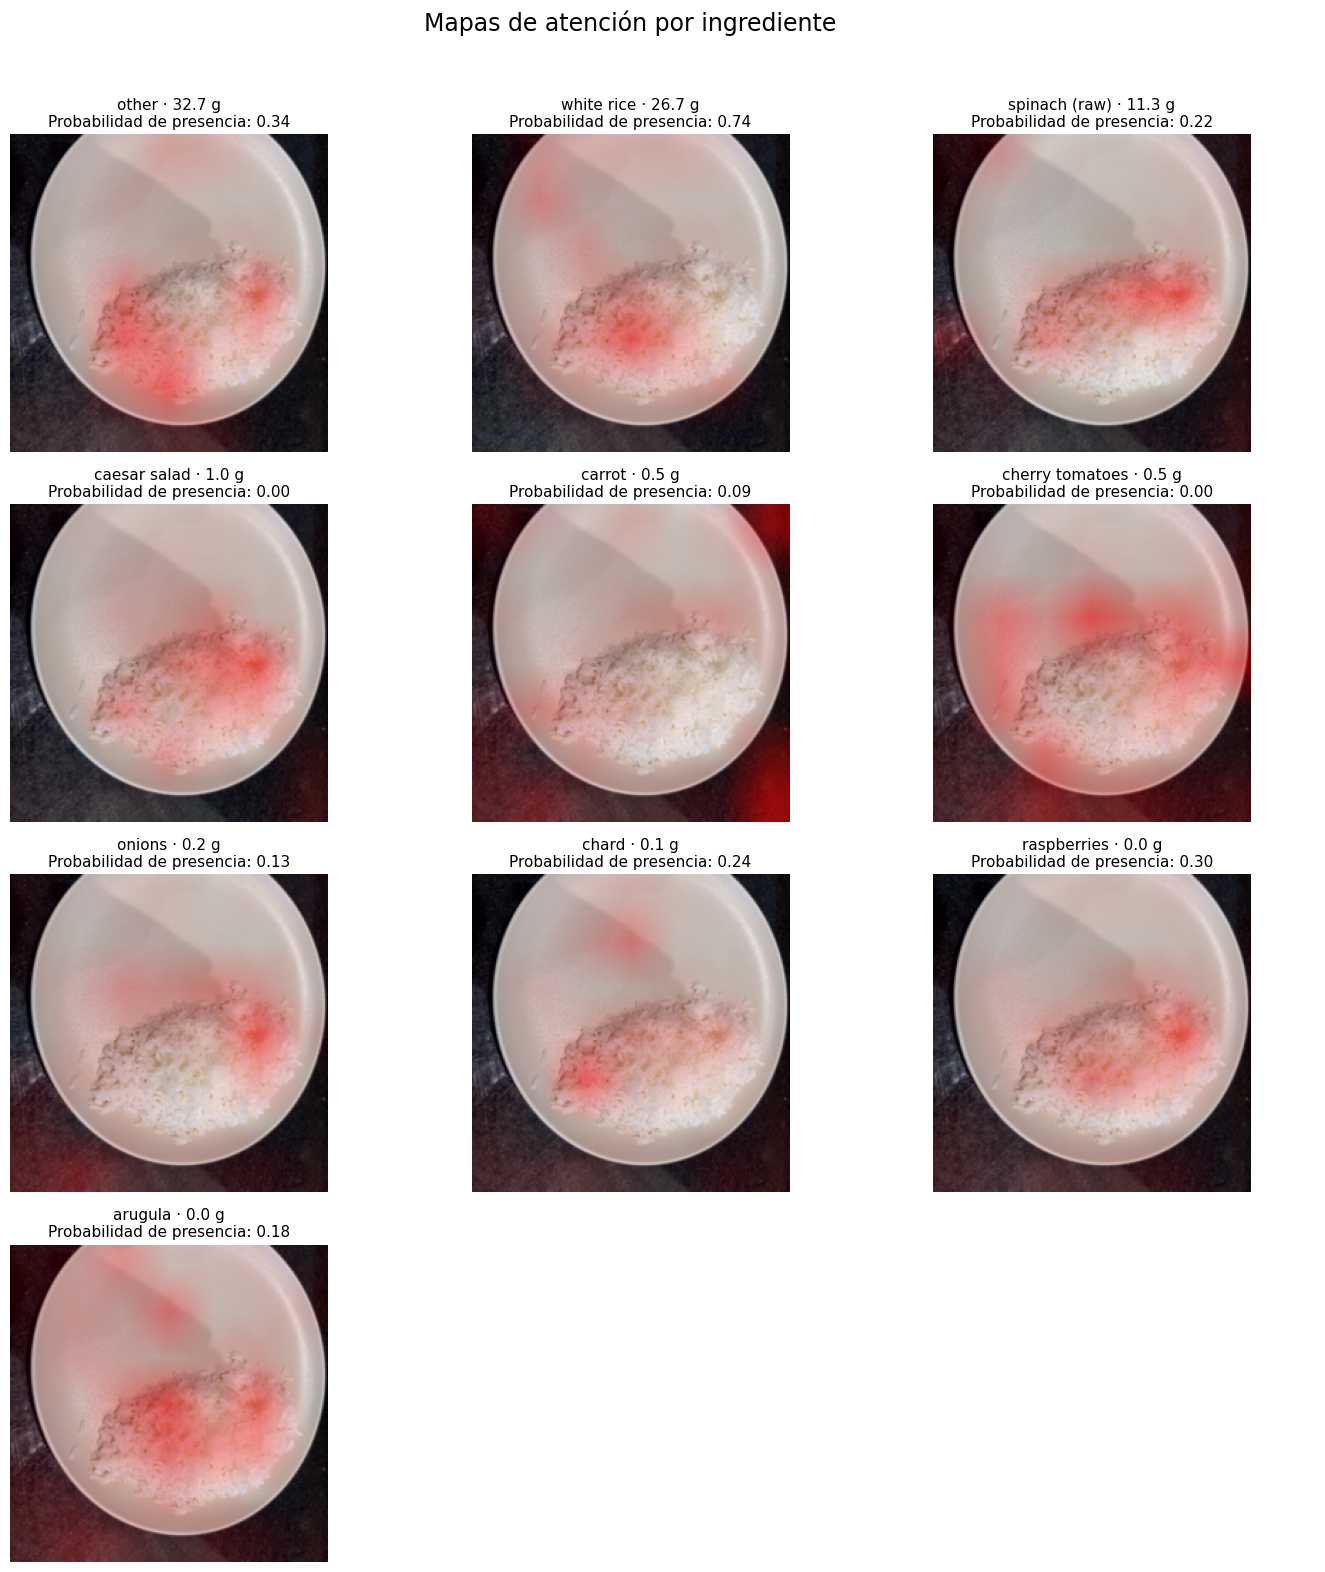

In [24]:
import json
import math
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, HTML

RESULTS = DRIVE / "predictions" / PHOTO.stem
report = json.loads((RESULTS / "prediction.json").read_text())
ingredients = sorted(
    report["ingredients"], key=lambda x: x["grams"], reverse=True
)[:10]
nutrition = report["nutrition"]

# Tarjetas de masa y nutrientes
cards = [
    ("Masa estimada", report["used_total_mass_grams"], "g"),
    ("Energía", nutrition["calories"], "kcal"),
    ("Proteínas", nutrition["protein"], "g"),
    ("Carbohidratos", nutrition["carbohydrates"], "g"),
    ("Grasas", nutrition["fat"], "g"),
]
display(HTML(
    '<div style="display:flex;flex-wrap:wrap;gap:12px;margin:18px 0">'
    + "".join(
        f'<div style="background:#182335;color:#fff;padding:18px;'
        f'border-radius:14px;min-width:135px">'
        f'<div style="font-size:13px;color:#bac8dc">{label}</div>'
        f'<div style="font-size:27px;font-weight:600">{value:.1f} '
        f'<span style="font-size:15px">{unit}</span></div></div>'
        for label, value, unit in cards
    )
    + "</div>"
))

# Imagen y distribución de gramos
fig, axes = plt.subplots(
    1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1.4]}
)
crop = RESULTS / "intermediates/input_crop.png"
with Image.open(crop) as img:
    axes[0].imshow(img)
axes[0].set_title("Imagen recibida por el modelo", fontsize=14)
axes[0].axis("off")

names = [x["name"] for x in ingredients]
grams = [x["grams"] for x in ingredients]
colors = ["#16a085" if x["recognized"] else "#aeb8c4" for x in ingredients]

bars = axes[1].barh(names, grams, color=colors, height=0.65)
axes[1].invert_yaxis()
axes[1].bar_label(bars, labels=[f"{g:.1f} g" for g in grams], padding=5)
axes[1].set_xlim(0, max(grams) * 1.25 + 1)
axes[1].set_xlabel("Gramos estimados")
axes[1].set_title("10 ingredientes con mayor masa estimada", fontsize=14)
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].grid(axis="x", alpha=0.15)
axes[1].set_axisbelow(True)
plt.tight_layout()
plt.show()

display(HTML(
    "<p><b>Verde:</b> supera el umbral de presencia. "
    "<b>Gris:</b> queda debajo del umbral, aunque recibe masa estimada. "
    "Los nutrientes incluyen las 100 clases, no solo estas diez.</p>"
))

# Galería de atención
maps = sorted((RESULTS / "intermediates").glob("*_attention.png"))
if maps:
    cols = 3
    rows = math.ceil(len(maps) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(14, rows * 4))
    axes = np.asarray(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for rank, (ax, path) in enumerate(zip(axes, maps)):
        with Image.open(path) as img:
            ax.imshow(img)
        item = ingredients[rank]
        ax.set_title(
            f"{item['name']} · {item['grams']:.1f} g\n"
            f"Probabilidad de presencia: {item['probability']:.2f}",
            fontsize=11,
        )

    fig.suptitle("Mapas de atención por ingrediente", fontsize=17)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

## 9.1 Ahora con test o validación

In [32]:
import json
import shutil
import subprocess
from pathlib import Path

SPLIT = "test"  # "validation" o "test"
INDEX = 20            # 0 = primer plato, 1 = segundo, etc.

records_path = PROJECT / "data/processed_100/records.jsonl"
with records_path.open() as source:
    records = [json.loads(line) for line in source if line.strip()]

selected = [r for r in records if r["split"] == SPLIT]
assert 0 <= INDEX < len(selected), f"INDEX debe estar entre 0 y {len(selected)-1}"
record = selected[INDEX]

# Cada imagen se llama rgb.png. Copiarla con el ID del plato
# evita que los resultados de distintos platos se sobrescriban.
image = DATA / record["image"]
folder = Path("/content/inference_inputs")
folder.mkdir(parents=True, exist_ok=True)
PHOTO = folder / f"{record['dish_id']}.png"
shutil.copy2(image, PHOTO)

assert CHECKPOINT.is_file(), "Falta el checkpoint calibrado."

print("Split:", SPLIT)
print("Plato:", record["dish_id"])

subprocess.run([
    sys.executable, "-u", "scripts/infer_image_model.py",
    "--checkpoint", str(CHECKPOINT),
    "--image", str(PHOTO),
    "--output-dir", str(DRIVE / "predictions"),
    "--device", "cuda",
    "--save-attention", "--top-k", "10",
], check=True)

print("\nValores REALES de la anotación:")
print(f"Masa total: {record['total_mass']:.1f} g")
for ingredient in sorted(
    record["ingredients"], key=lambda x: x["grams"], reverse=True
):
    print(f"{ingredient['name']}: {ingredient['grams']:.1f} g")

Split: test
Plato: dish_1558030383

Valores REALES de la anotación:
Masa total: 26.0 g
bacon: 26.0 g


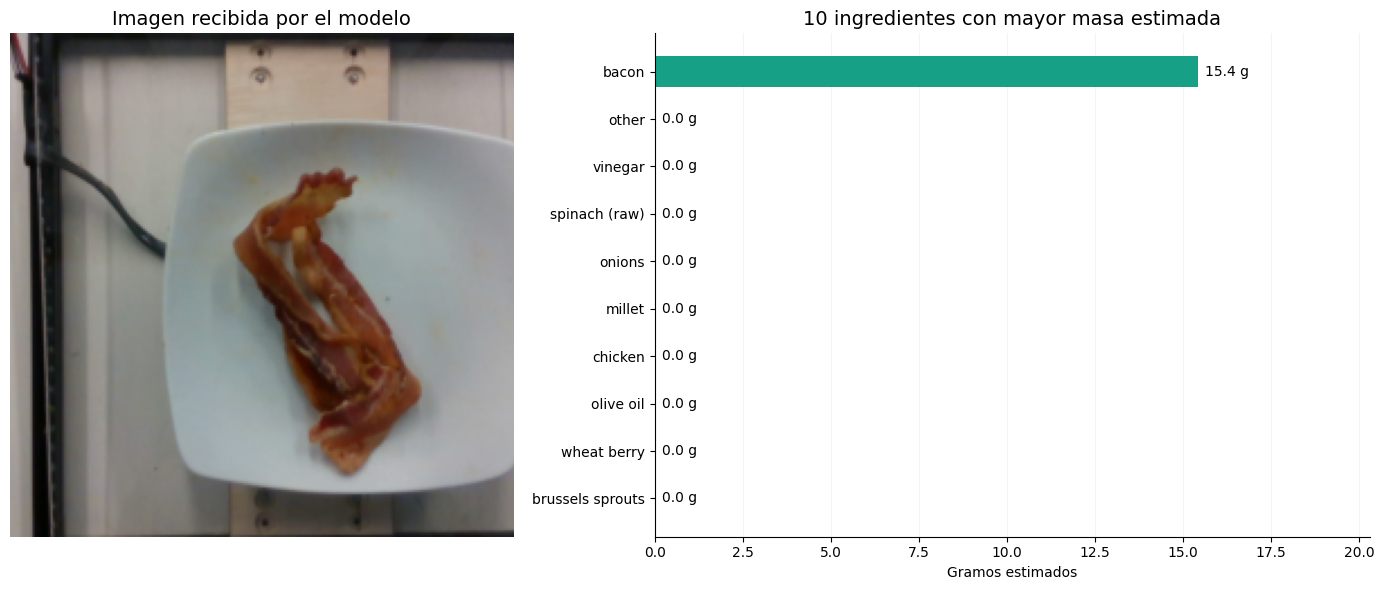

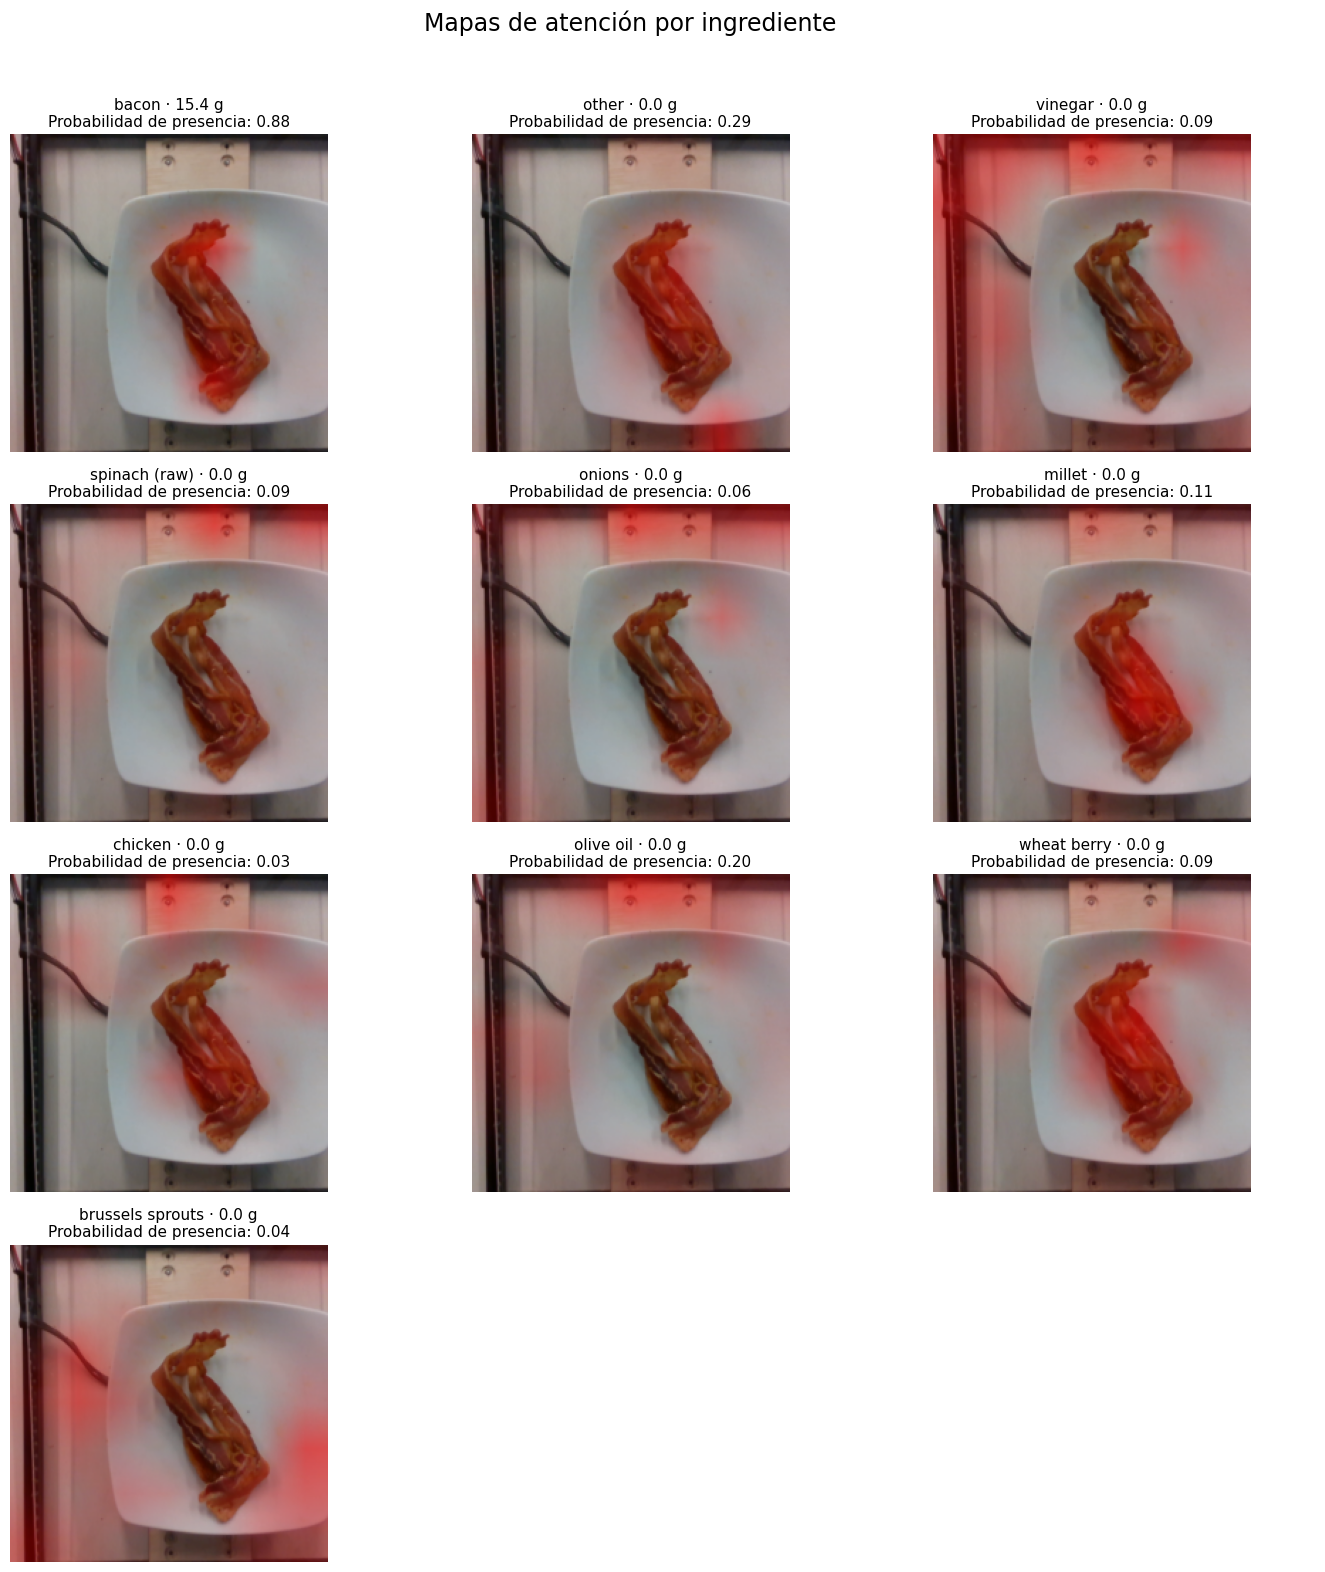

In [33]:
RESULTS = DRIVE / "predictions" / PHOTO.stem
report = json.loads((RESULTS / "prediction.json").read_text())
ingredients = sorted(
    report["ingredients"], key=lambda x: x["grams"], reverse=True
)[:10]
nutrition = report["nutrition"]

# Tarjetas de masa y nutrientes
cards = [
    ("Masa estimada", report["used_total_mass_grams"], "g"),
    ("Energía", nutrition["calories"], "kcal"),
    ("Proteínas", nutrition["protein"], "g"),
    ("Carbohidratos", nutrition["carbohydrates"], "g"),
    ("Grasas", nutrition["fat"], "g"),
]
display(HTML(
    '<div style="display:flex;flex-wrap:wrap;gap:12px;margin:18px 0">'
    + "".join(
        f'<div style="background:#182335;color:#fff;padding:18px;'
        f'border-radius:14px;min-width:135px">'
        f'<div style="font-size:13px;color:#bac8dc">{label}</div>'
        f'<div style="font-size:27px;font-weight:600">{value:.1f} '
        f'<span style="font-size:15px">{unit}</span></div></div>'
        for label, value, unit in cards
    )
    + "</div>"
))

# Imagen y distribución de gramos
fig, axes = plt.subplots(
    1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1.4]}
)
crop = RESULTS / "intermediates/input_crop.png"
with Image.open(crop) as img:
    axes[0].imshow(img)
axes[0].set_title("Imagen recibida por el modelo", fontsize=14)
axes[0].axis("off")

names = [x["name"] for x in ingredients]
grams = [x["grams"] for x in ingredients]
colors = ["#16a085" if x["recognized"] else "#aeb8c4" for x in ingredients]

bars = axes[1].barh(names, grams, color=colors, height=0.65)
axes[1].invert_yaxis()
axes[1].bar_label(bars, labels=[f"{g:.1f} g" for g in grams], padding=5)
axes[1].set_xlim(0, max(grams) * 1.25 + 1)
axes[1].set_xlabel("Gramos estimados")
axes[1].set_title("10 ingredientes con mayor masa estimada", fontsize=14)
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].grid(axis="x", alpha=0.15)
axes[1].set_axisbelow(True)
plt.tight_layout()
plt.show()

display(HTML(
    "<p><b>Verde:</b> supera el umbral de presencia. "
    "<b>Gris:</b> queda debajo del umbral, aunque recibe masa estimada. "
    "Los nutrientes incluyen las 100 clases, no solo estas diez.</p>"
))

# Galería de atención
maps = sorted((RESULTS / "intermediates").glob("*_attention.png"))
if maps:
    cols = 3
    rows = math.ceil(len(maps) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(14, rows * 4))
    axes = np.asarray(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for rank, (ax, path) in enumerate(zip(axes, maps)):
        with Image.open(path) as img:
            ax.imshow(img)
        item = ingredients[rank]
        ax.set_title(
            f"{item['name']} · {item['grams']:.1f} g\n"
            f"Probabilidad de presencia: {item['probability']:.2f}",
            fontsize=11,
        )

    fig.suptitle("Mapas de atención por ingrediente", fontsize=17)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

## Archivos persistentes

- `runs/query2label_100_asl/`: checkpoints completos, config, historial y validación más reciente.
- `torch_cache/`: pesos ImageNet descargados al comenzar una corrida nueva.
- `reports/query2label_asl_validation/`: métricas y `calibrated.pt`.
- `reports/query2label_asl_test/`: métricas y predicciones de test.
- `predictions/plato/`: predicción e intermedios de la foto.

Para inferencia local alcanza con descargar `best.pt` o `calibrated.pt` y usar los scripts con `--device cpu`. Para reanudar entrenamiento conservar `last.pt` y toda la carpeta de corrida. No se necesitan Depth Anything, pesos OmniFood ni extracción de vectores.
